In [1]:
import pandas as pd
import matplotlib
print(pd.__version__, matplotlib.__version__)

3.0.5 3.11.2


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

DATA = "../../data/interim/nei_cleaned.csv"
FIG = "../../reports/figures"
os.makedirs(FIG, exist_ok=True)

df = pd.read_csv(DATA, low_memory=False)
df.head()

,objectid,nei_id,year,municipality,business_name,business_street_number,business_street_name,business_unit,business_po_box,business_postal_code,...,secondary_naics,primary_sector,industry,opening_year,floor_size_sqft,size_range_of_employees,x,y,postal_code_status,nei_id_conflict
0,1,9697,2024,Grimsby,Niagara Wine and Brew Co.,80,Main Street West,5,NaN,L3M 1R6,...,312130.0,Manufacturing,Breweries,1998.0,NaN,Small (5-99 Employees),-8.856962e+06,5.341728e+06,Valid,False
1,2,3516,2024,St. Catharines,Dr. Todd Watts,221,Glendale Avenue,NaN,NaN,L2T 2K9,...,NaN,Health care and social assistance,Offices of dentists,1998.0,NaN,Undetermined,-8.819383e+06,5.332803e+06,Valid,False
2,3,60289,2024,St. Catharines,Minuteman Press,184,Scott Street,1,NaN,L2N 1H1,...,323113.0,Manufacturing,Other printing,2023.0,NaN,Micro (1-4 Employees),-8.821726e+06,5.339761e+06,Valid,False
3,4,7343,2024,Welland,Heather Raso Chartered Accountant Professional...,325,Thorold Road,1040,NaN,L3C 3W4,...,541213.0,"Professional, scientific and technical services",Offices of accountants,2009.0,1020.0,Micro (1-4 Employees),-8.824543e+06,5.312412e+06,Valid,False
4,5,51250,2024,Port Colborne,Port Colborne Tailoring,229,Main Street West,NaN,NaN,L3K 3V7,...,NaN,Other services (except public administration),Other personal and household goods repair and ...,2023.0,NaN,Micro (1-4 Employees),-8.822407e+06,5.296754e+06,Valid,False


In [3]:
print(df.shape)
print(list(df.columns))
cols = ["municipality", "industry", "primary_sector", "size_range_of_employees"]
df[cols].isna().sum()

(98065, 22)
['objectid', 'nei_id', 'year', 'municipality', 'business_name', 'business_street_number', 'business_street_name', 'business_unit', 'business_po_box', 'business_postal_code', 'business_website', 'primary_naics', 'secondary_naics', 'primary_sector', 'industry', 'opening_year', 'floor_size_sqft', 'size_range_of_employees', 'x', 'y', 'postal_code_status', 'nei_id_conflict']


municipality               0
industry                   0
primary_sector             0
size_range_of_employees    0
dtype: int64

In [4]:
print(df["postal_code_status"].value_counts(dropna=False))
print(df["nei_id_conflict"].value_counts(dropna=False))
print("distinct nei_id:", df["nei_id"].nunique())

postal_code_status
Valid               97785
Invalid - Review      153
Missing               127
Name: count, dtype: int64
nei_id_conflict
False    97787
True       278
Name: count, dtype: int64
distinct nei_id: 15846


## Data and limitations

- **Source:** `data/interim/nei_cleaned.csv`, 98,065 rows and 22 columns. The last two columns, `postal_code_status` and `nei_id_conflict`, were added in commit `c70b233` and are not used in this analysis.
- **Records, not businesses:** each row is a business record for one survey year. There are 15,846 distinct `nei_id` values across 98,065 records, so the same business can appear several times.
- **Survey years:** 2016 to 2019 and 2022 to 2025. There are no 2020 or 2021 records.
- **Missing values:** `municipality`, `industry`, `primary_sector` and `size_range_of_employees` have no missing values. 
- **Flags:** 278 records have `nei_id_conflict` set to True. In the NEI cleaning notebook (Steps 10B and 10F), a record is flagged when the same `nei_id` appears in the same year with more than one business name. So `nei_id` is not a fully reliable business identifier. 153 postal codes are flagged "Invalid - Review" and 127 are "Missing". The flags were added in commit `c70b233` and were not used in this analysis.
- **What this data cannot tell us:** owner age, retirement intention, succession plans or why a business closed.
- **Sector labels:** `primary_sector` has 50 distinct values, including capitalisation variants (such as "Retail trade" and "Retail Trade") and a few industry-level values. The charts use the labels as they are in the file; the variants hold a very small share of records.
- **Columns used:** municipality = `municipality`; industry = `primary_sector` (broad sector, used for the chart) and `industry` (detailed, 973 distinct values); employee size = `size_range_of_employees`.

municipality
St. Catharines         32885
Niagara Falls          22430
Welland                 9741
Fort Erie               6224
Niagara-on-the-Lake     4863
Lincoln                 4644
Thorold                 4443
Grimsby                 4009
Port Colborne           3874
Pelham                  2815
West Lincoln            1600
Wainfleet                537
Name: count, dtype: int64


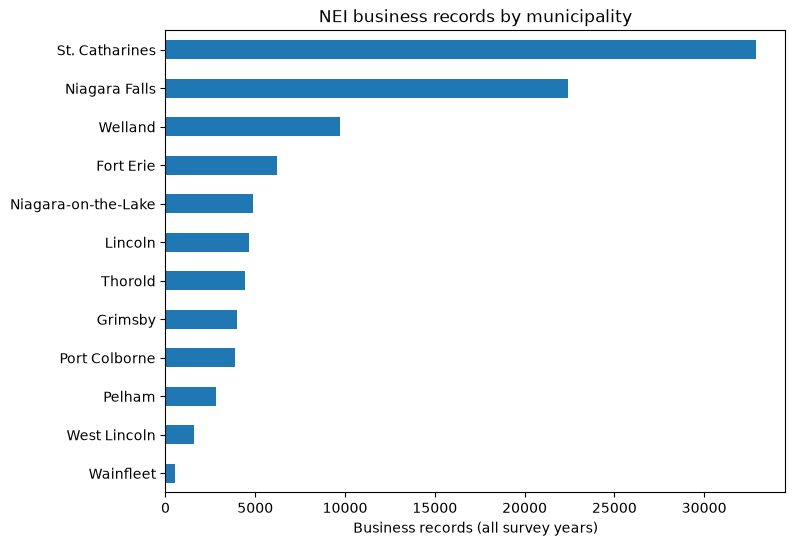

In [5]:
muni = df["municipality"].value_counts()
print(muni)
ax = muni.sort_values().plot(kind="barh", figsize=(8, 6))
ax.set_xlabel("Business records (all survey years)")
ax.set_ylabel("")
ax.set_title("NEI business records by municipality")
plt.savefig(f"{FIG}/nei_municipality_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


What the chart shows: the number of NEI business records in each of the 12 Niagara municipalities, summed across all survey years (2016 to 2019 and 2022 to 2025).

What I observed: St. Catharines (32,885) and Niagara Falls (22,430) account for about 56% of all 98,065 records, and the top three municipalities, with Welland, account for about two-thirds. Wainfleet (537) and West Lincoln (1,600) have the fewest.

Why it matters: recorded businesses are heavily concentrated in a few municipalities, so results for the Niagara region as a whole will be driven mainly by them, and the municipalities with the fewest records (such as Wainfleet and West Lincoln) have very small samples.

What the data cannot tell us: these are business records, not unique businesses. The same business can appear in several years (15,846 distinct nei_id values across 98,065 records). The counts are also not adjusted for population or land area, don’t measure employment, and say nothing about owner age, succession plans or closure risk.



distinct sectors: 50 | distinct industries: 973
primary_sector
Retail trade                                                             21898
Accommodation and food services                                          14235
Other services (except public administration)                            13249
Health care and social assistance                                        10444
Manufacturing                                                             6668
Professional, scientific and technical services                           6106
Finance and insurance                                                     3736
Arts, entertainment and recreation                                        3242
Construction                                                              3145
Real estate and rental and leasing                                        2450
Administrative and support, waste management and remediation services     2334
Wholesale trade                                                     

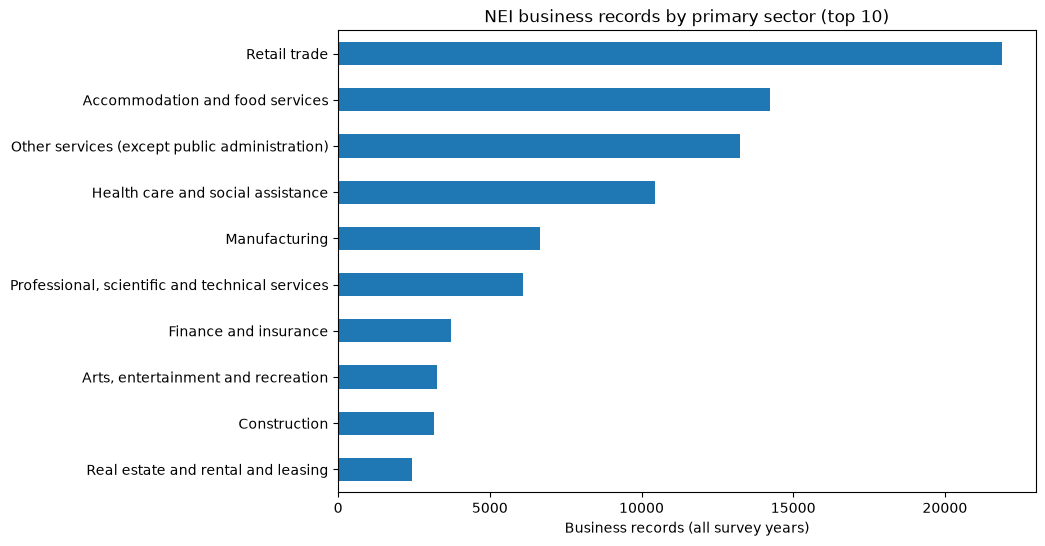

In [6]:
print("distinct sectors:", df["primary_sector"].nunique(), "| distinct industries:", df["industry"].nunique())
sector = df["primary_sector"].value_counts()
print(sector)
ax = sector.head(10).sort_values().plot(kind="barh", figsize=(9, 6))
ax.set_xlabel("Business records (all survey years)")
ax.set_ylabel("")
ax.set_title("NEI business records by primary sector (top 10)")
plt.savefig(f"{FIG}/nei_sector_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

What the chart shows: the number of NEI business records in each of the 10 largest primary sectors, summed across all survey years.

What I observed: Retail trade (21,898 records) is the largest sector, followed by Accommodation and food services (14,235), Other services (13,249) and Health care and social assistance (10,444). These four hold about 61% of all records, and the top 10 about 87%. Manufacturing is fifth (6,668).

Why it matters: Recorded Niagara businesses are concentrated in a few sectors (retail trade, accommodation and food services, other services, and health care and social assistance), so any later analysis of the whole region will mostly reflect those sectors.

What the data cannot tell us: These are business records, not unique businesses or jobs, so a sector with many small businesses may look bigger than its share of employment. primary_sector has 50 distinct values because of spelling and capitalisation variants (for example “Retail trade”, “Retail Trade” and “retail trade”), and it holds a few industry-level values, so the counts of small groups are unreliable. The data also says nothing about owner age or succession.

In [7]:
print("distinct sectors:", df["primary_sector"].nunique())
print("after ignoring capitalisation and extra spaces:", df["primary_sector"].str.strip().str.lower().nunique())
print(sector.tail(15))

distinct sectors: 50
after ignoring capitalisation and extra spaces: 23
primary_sector
arts, entertainment and recreation                                       3
utilities                                                                2
Public Administration                                                    2
Professional, Scientific and technical services                          2
finance and insurance                                                    2
Finance and Insurance                                                    1
transportation and warehousing                                           1
information and cultural industries                                      1
Arts, Entertainment and Recreation                                       1
administrative and support, waste management and remediation services    1
Professional, Scientific and technical Services                          1
Social Organization                                                      1
Other Service

size_range_of_employees
Small (5-99 Employees)          37584
Micro (1-4 Employees)           26606
Permanently Closed or Vacant    17809
Undetermined                    14075
Medium (100-499 Employees)       1700
Large (500 + Employees)           209
Zero Employees                     32
Aggregate                          22
Small                              15
Micro                               9
Medium                              3
Large                               1
Name: count, dtype: int64


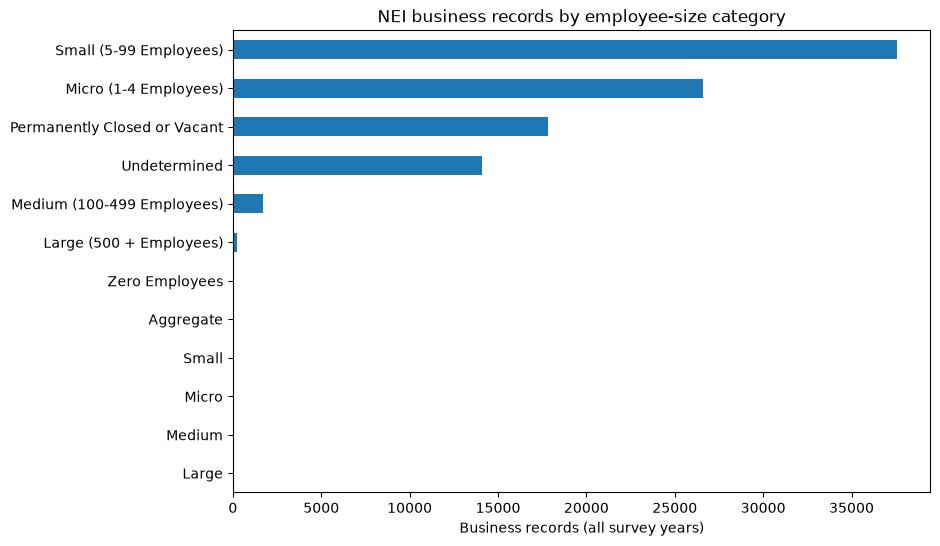

In [8]:
size = df["size_range_of_employees"].value_counts()
print(size)
ax = size.sort_values().plot(kind="barh", figsize=(9, 6))
ax.set_xlabel("Business records (all survey years)")
ax.set_ylabel("")
ax.set_title("NEI business records by employee-size category")
plt.savefig(f"{FIG}/nei_size_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

What the chart shows: The number of NEI business records in each employee-size category, summed across all survey years. The categories are used exactly as they appear in the file.

What I observed: Small businesses (5-99 employees) are the largest group with 37,584 records, followed by Micro (1-4 employees) with 26,606. Medium (1,700) and Large (209) are very few. About 18% of records are labelled “Permanently Closed or Vacant” and about 14% “Undetermined”, so about a third of records have no size band. Among the four ranged bands (Micro, Small, Medium and Large), Micro and Small together make up about 97% of records.

Why it matters: Recorded Niagara businesses are overwhelmingly small among records with a size band, which fits a project focused on small-business succession.

What the data cannot tell us: The file gives size ranges only, not employee counts, so it can’t show total employment. The Small band spans 5 to 99 employees, so it hides large differences. The result depends on how the roughly one third of records without a size would be distributed. These are records, not unique businesses, and the data says nothing about owner age or succession plans.

In [9]:
print(df.columns.tolist())

['objectid', 'nei_id', 'year', 'municipality', 'business_name', 'business_street_number', 'business_street_name', 'business_unit', 'business_po_box', 'business_postal_code', 'business_website', 'primary_naics', 'secondary_naics', 'primary_sector', 'industry', 'opening_year', 'floor_size_sqft', 'size_range_of_employees', 'x', 'y', 'postal_code_status', 'nei_id_conflict']


**Employment information:** the dataset has no column with exact employee counts. The only employment information is `size_range_of_employees`, which holds size ranges and some non-size labels ("Permanently Closed or Vacant", "Undetermined"). Floor size (`floor_size_sqft`) measures area, not employment. Total employment cannot be calculated from these columns without inventing numbers, so it is not estimated here.